In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from statsmodels.tsa.seasonal import MSTL
from xgboost import XGBRegressor
from scipy import stats
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, ccf, kpss
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


1. Set time

In [2]:

df = pd.read_csv('energy_dataset.csv')
df['time'] = pd.to_datetime(df['time'], utc=True)
df = df.set_index('time').sort_index()
df = df.tz_convert("Europe/Madrid")

excepted_time = pd.date_range(df.index.min(), df.index.max(), freq='h')
assert df.index.equals(excepted_time), 'Check time first'
df.head()

,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,...,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
time,,,,,,,,,,,,,,,,,,,,,
2015-01-01 00:00:00+01:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,NaN,...,196.0,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41
2015-01-01 01:00:00+01:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,NaN,...,195.0,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92
2015-01-01 02:00:00+01:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,NaN,...,196.0,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48
2015-01-01 03:00:00+01:00,438.0,254.0,0.0,4314.0,4131.0,160.0,0.0,0.0,0.0,NaN,...,191.0,0.0,5238.0,2.0,NaN,5151.0,22642.0,21286.0,42.27,59.32
2015-01-01 04:00:00+01:00,428.0,187.0,0.0,4130.0,3840.0,156.0,0.0,0.0,0.0,NaN,...,189.0,0.0,4935.0,9.0,NaN,4861.0,21785.0,20264.0,38.41,56.04


2. Check NA and duplicated

In [3]:
print(len(df))
df_audit = pd.DataFrame({
    'recorded values': df.count(),
    'recorded zero': df.eq(0).sum(),
    'NaN values': df.isna().sum(),
    'duplicated': df.index.duplicated().sum()
})
df_audit

35064


,recorded values,recorded zero,NaN values,duplicated
generation biomass,35045,4,19,0
generation fossil brown coal/lignite,35046,10517,18,0
generation fossil coal-derived gas,35046,35046,18,0
generation fossil gas,35046,1,18,0
generation fossil hard coal,35046,3,18,0
generation fossil oil,35045,3,19,0
generation fossil oil shale,35046,35046,18,0
generation fossil peat,35046,35046,18,0
generation geothermal,35046,35046,18,0
generation hydro pumped storage aggregated,0,0,35064,0


In [ ]:
supply = df.drop(columns=['generation fossil coal-derived gas', 'generation fossil oil shale', 'generation fossil peat',
                          'generation geothermal', 'generation hydro pumped storage aggregated', 'generation marine',
                          'generation wind offshore', 'forecast solar day ahead', 'forecast wind offshore eday ahead', 
                          'forecast wind onshore day ahead', 'total load forecast']).copy()
supply.columns = supply.columns.str.removeprefix('generation ')
supply[supply.isnull().any(axis=1)].head(5)


,biomass,fossil brown coal/lignite,fossil gas,fossil hard coal,fossil oil,hydro pumped storage consumption,hydro run-of-river and poundage,hydro water reservoir,nuclear,other,other renewable,solar,waste,wind onshore,total load actual,price day ahead,price actual
time,,,,,,,,,,,,,,,,,
2015-01-05 03:00:00+01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21182.0,35.2,59.68
2015-01-05 12:00:00+01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.5,79.14
2015-01-05 13:00:00+01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.8,73.95
2015-01-05 14:00:00+01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32.5,71.93
2015-01-05 15:00:00+01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,71.50


In [74]:
supply_filled = supply.interpolate(method='time', limit_area='inside')
print(supply_filled.isna().sum())

biomass                             0
fossil brown coal/lignite           0
fossil gas                          0
fossil hard coal                    0
fossil oil                          0
hydro pumped storage consumption    0
hydro run-of-river and poundage     0
hydro water reservoir               0
nuclear                             0
other                               0
other renewable                     0
solar                               0
waste                               0
wind onshore                        0
total load actual                   0
price day ahead                     0
price actual                        0
business hour                       0
hour_sin                            0
hour_cos                            0
month_sin                           0
month_cos                           0
weekday_sin                         0
weekday_cos                         0
dtype: int64


Find outliers

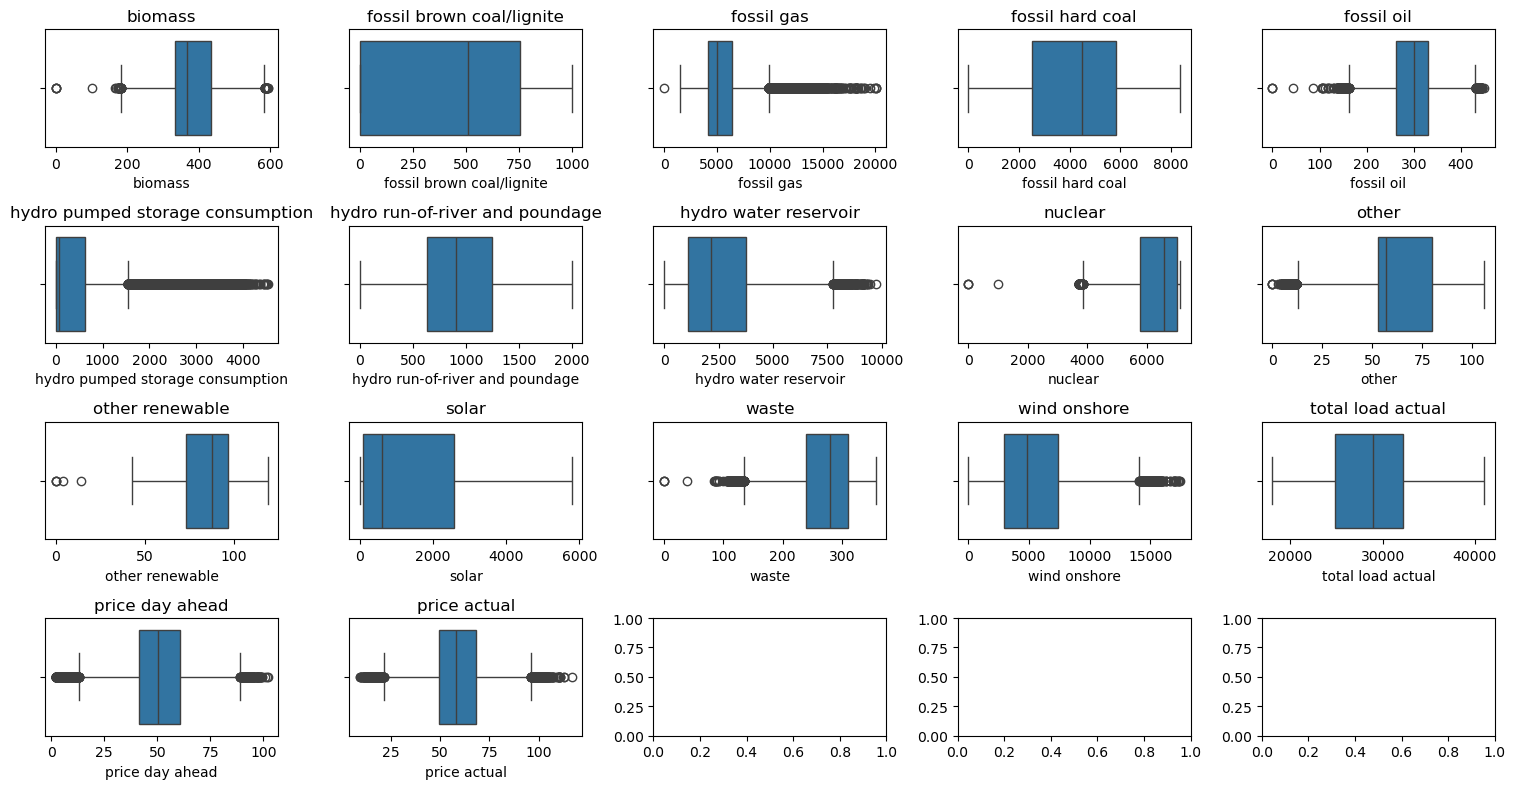

In [5]:
fig, axes = plt.subplots(4, 5, figsize=(15, 8))
for column, ax in zip(supply.columns, axes.flat):
    sns.boxplot(ax=ax, x=supply[column])
    ax.set_title(column)
plt.tight_layout()
plt.show()

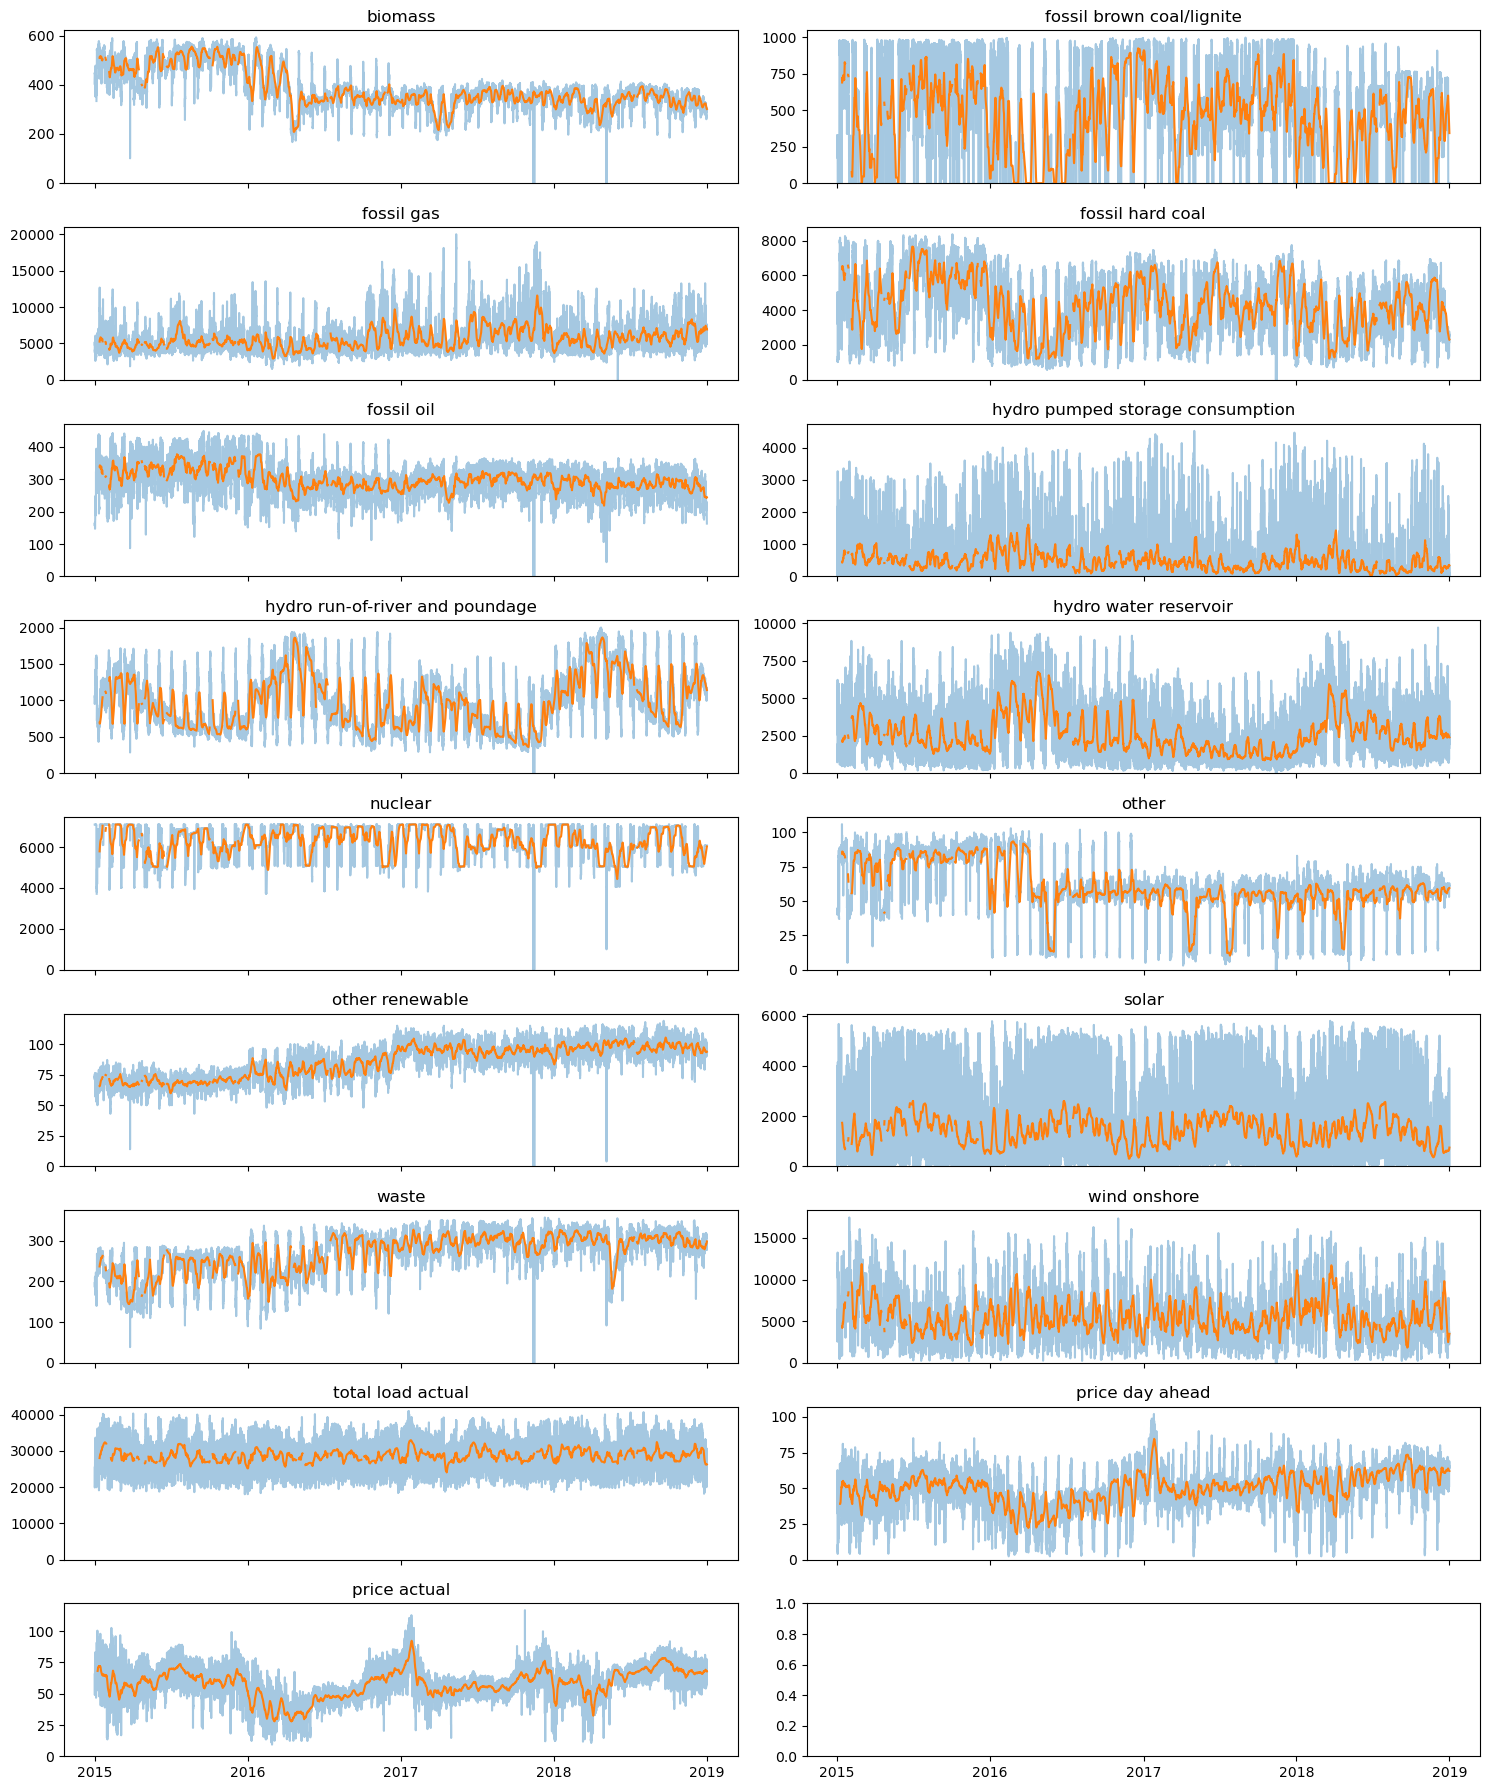

In [6]:
fig, axes = plt.subplots(9, 2, figsize=(15, 18), sharex=True)
for column, ax in zip(supply.columns, axes.flat):
    ax.plot(supply.index, supply[column], alpha=0.4, color='tab:blue')
    ax.plot(supply.index, supply[column].rolling(7*24).mean(), color='tab:orange')
    ax.set_ylim(bottom=0)
    ax.set_title(column)
axes[-1, 0].xaxis.set_major_locator(mdates.YearLocator())
plt.tight_layout()
plt.show()

IQR rule (boxplot whiskers): 699 hours flagged | robust rolling z-score > 5: 29 hours


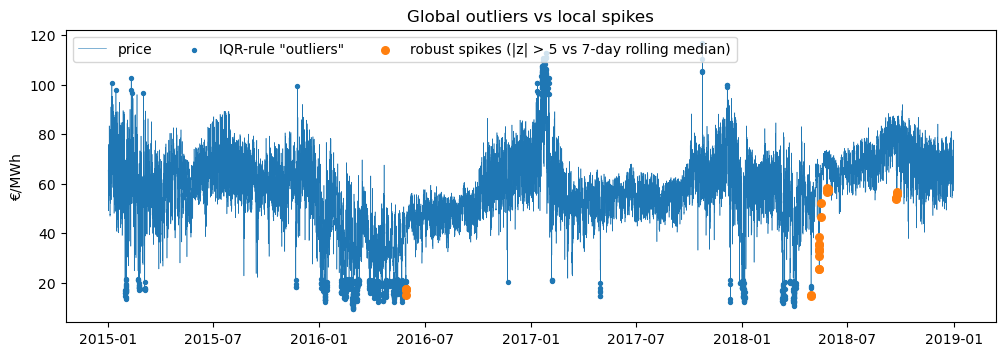

In [83]:
rolling_median = supply['price actual'].rolling(24 * 7, center=True, min_periods=24).median()

rolling_mad = ((supply['price actual'] - rolling_median).abs().rolling(24 * 7, center=True, min_periods=24).median())

robust_z = (supply['price actual'] - rolling_median) / (1.4826 * rolling_mad)
spikes = robust_z.abs() > 5

q1, q3 = supply['price actual'].quantile([0.25, 0.75])

iqr_flags = ((supply['price actual'] < q1 - 1.5 * (q3 - q1))| (supply['price actual'] > q3 + 1.5 * (q3 - q1)))

print(
    f'IQR rule (boxplot whiskers): {iqr_flags.sum()} hours flagged | '
    f'robust rolling z-score > 5: {spikes.sum()} hours'
)

fig, ax = plt.subplots(figsize=(12, 3.8))

ax.plot(supply['price actual'].index, supply['price actual'], linewidth=0.4, label='price')

ax.scatter(supply['price actual'].index[iqr_flags], supply['price actual'][iqr_flags], s=8, label='IQR-rule "outliers"',zorder=2)

ax.scatter(supply['price actual'].index[spikes], supply['price actual'][spikes], s=30, linewidth=1,
           label='robust spikes (|z| > 5 vs 7-day rolling median)',zorder=3)

ax.set(title='Global outliers vs local spikes', ylabel='€/MWh')

ax.legend(loc='upper left', ncol=3)

plt.show()

Analyze solar

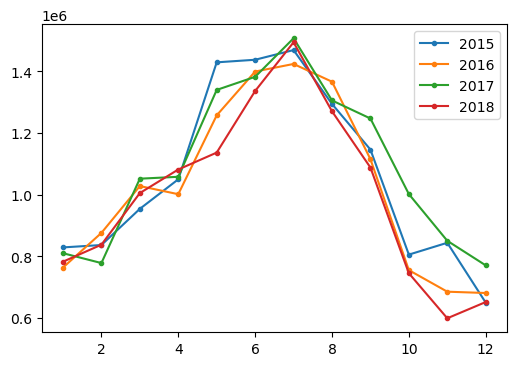

In [7]:
solar_monthly = supply['solar'].resample('MS').sum()
profile = solar_monthly.groupby([solar_monthly.index.year, solar_monthly.index.month]).sum().unstack(level=0)

fig, ax = plt.subplots(figsize=(6, 4))
for year in profile.columns:
    ax.plot(profile.index, profile[year], '.-', label=year)

ax.legend()
plt.show()

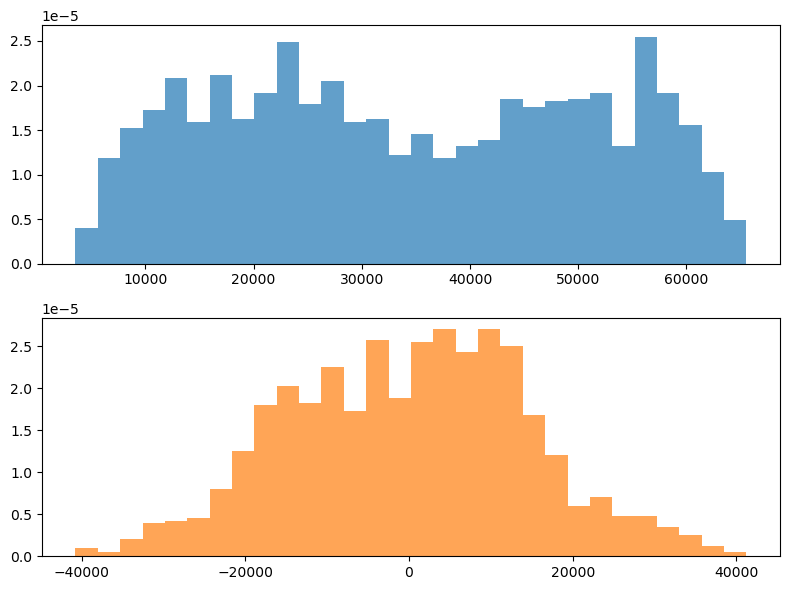

In [8]:
solar_daily = supply['solar'].resample('D').sum()
month_mean= solar_daily.groupby(solar_daily.index.month).transform('mean')
solar_daily_adjusted = solar_daily - month_mean

fig, axes = plt.subplots(2, 1, figsize=(8, 6))
axes[0].hist(solar_daily.dropna(), bins=30, color='tab:blue', density=True, alpha=0.7)
axes[1].hist(solar_daily_adjusted.dropna(), bins=30, color='tab:orange', density=True, alpha=0.7)
plt.tight_layout()
plt.show()

,n,skewness,kurtosis
origin,1461.0,0.039571,-1.267427
monthly mean adjusted,1461.0,0.001856,-0.340081
YoeJohnson transformed,1461.0,0.067606,-0.325721


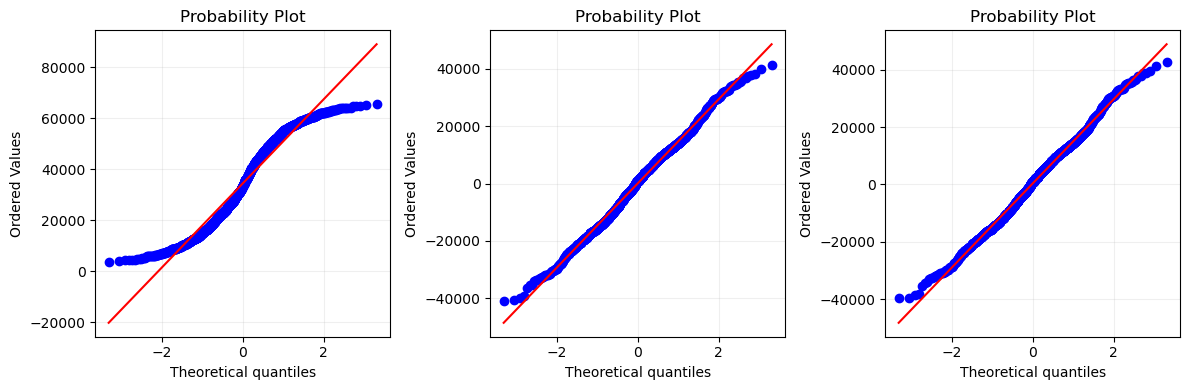

In [9]:
def distribution_summary(series):
    series.dropna()
    return pd.Series({'n': len(series), 'skewness': series.skew(), 'kurtosis': series.kurtosis()})

transformed_values, fit_lambda = stats.yeojohnson(solar_daily_adjusted.dropna().to_numpy())
transformed = pd.Series(transformed_values, index=solar_daily_adjusted.index, name='YeoJohnson')

description = pd.DataFrame({
    'origin': distribution_summary(solar_daily),
    'monthly mean adjusted': distribution_summary(solar_daily_adjusted),
    'YoeJohnson transformed': distribution_summary(transformed)
}).T
display(description)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, series, label in zip(axes, [solar_daily, solar_daily_adjusted, transformed], ['Original', 'Monthly adjusted', 'Yeo-Johnson adjusted']):
    stats.probplot(series.dropna(), dist='norm', plot=ax)
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

Analyze water

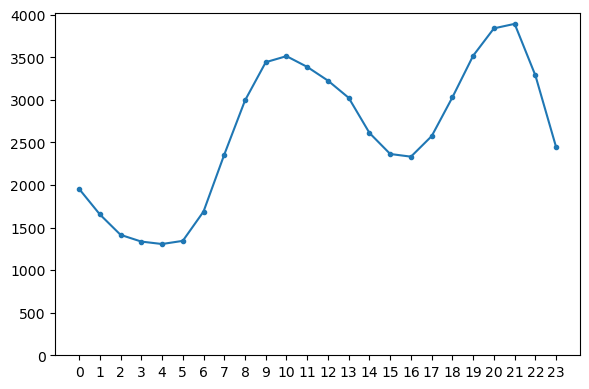

In [10]:
water_hourly_mean = supply['hydro water reservoir'].groupby(supply.index.hour).mean()
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(water_hourly_mean.index, water_hourly_mean, '.-')
ax.set_ylim(bottom=0)
ax.set_xticks(range(24))
fig.tight_layout()
plt.show()

price actual analysis

n           35064.000000
skewness       -0.323749
kurtosis        0.469561
dtype: float64
n           35064.000000
skewness        0.008589
kurtosis        0.277816
dtype: float64


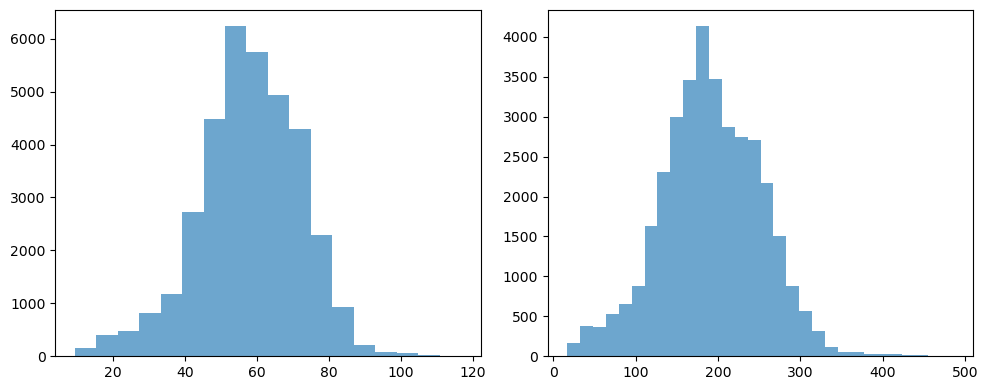

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
values = supply['price actual'].dropna()
axes[0].hist(values, bins=18, alpha=0.65,)
print(distribution_summary(supply['price actual']))

transformed_values, fit_lambda = stats.yeojohnson(values.dropna().to_numpy())
transformed = pd.Series(transformed_values, index=values.index, name='YeoJohnson')
axes[1].hist(transformed, bins=30, alpha=0.65)
print(distribution_summary(transformed))
plt.tight_layout()
plt.show()

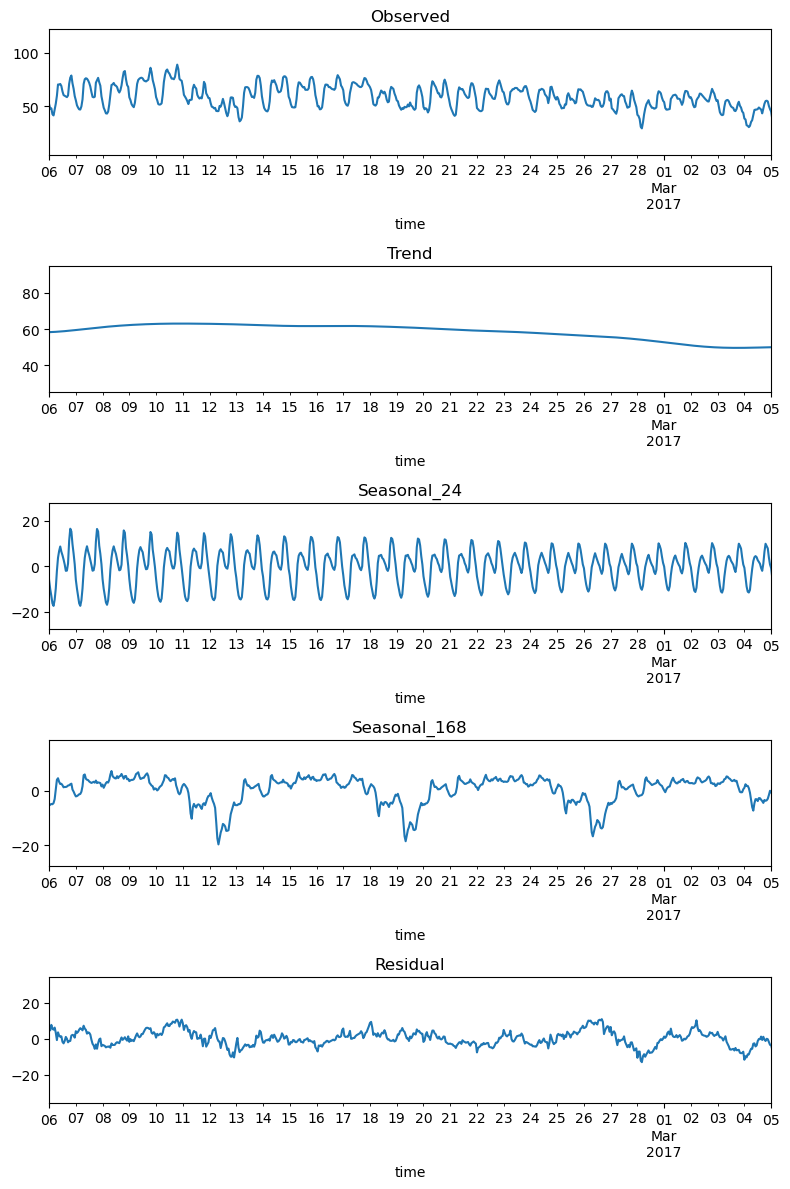

In [68]:
solar_mstl = MSTL(supply['price actual'], periods=(24, 24*7)).fit()
# window = solar_mstl.loc['2017-02-06': '2017-03-05']
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(5, 1, figsize=(8, 12))
solar_mstl.observed.plot(ax=ax1, title='Observed')
solar_mstl.trend.plot(ax=ax2, title='Trend')
solar_mstl.seasonal['seasonal_24'].plot(ax=ax3, title='Seasonal_24')
solar_mstl.seasonal['seasonal_168'].plot(ax=ax4, title='Seasonal_168')
solar_mstl.resid.plot(ax=ax5, title='Residual')
ax1.set_xlim(['2017-02-06', '2017-03-05'])
ax2.set_xlim(['2017-02-06', '2017-03-05'])
ax3.set_xlim(['2017-02-06', '2017-03-05'])
ax4.set_xlim(['2017-02-06', '2017-03-05'])
ax5.set_xlim(['2017-02-06', '2017-03-05'])
plt.tight_layout()
plt.show()

In [73]:
def stationarity_test(series):
    adf_stat, adf_p, *_ = adfuller(series, autolag='AIC')
    kpss_stat, kpss_p, *_ = kpss(series, regression='c', nlags='auto')
    return pd.Series({'ADF statistic:': adf_stat, 'ADF p-value':adf_p,
                      'KPSS statistic': kpss_stat, 'KPSS p-value': kpss_p})

pd.DataFrame({'price level': stationarity_test(supply['price actual']),
              'price diff level': stationarity_test(supply['price actual'].diff().dropna())}).T

/var/folders/4p/d5939nzx1cx141twsl1225j00000gn/T/ipykernel_65876/3560304517.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_stat, kpss_p, *_ = kpss(series, regression='c', nlags='auto')
/var/folders/4p/d5939nzx1cx141twsl1225j00000gn/T/ipykernel_65876/3560304517.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, *_ = kpss(series, regression='c', nlags='auto')


,ADF statistic:,ADF p-value,KPSS statistic,KPSS p-value
price level,-9.147016,2.750493e-15,4.330034,0.01
price diff level,-32.286286,0.000000e+00,0.015223,0.10


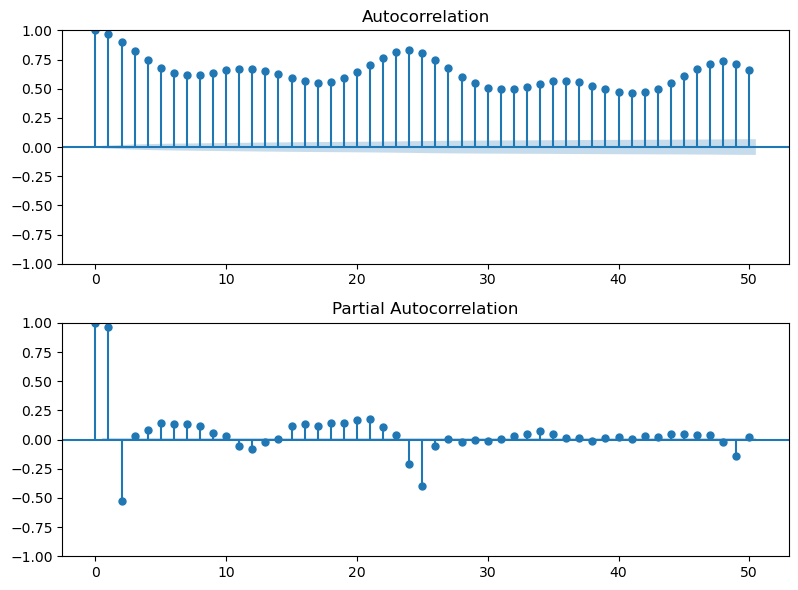

In [13]:
fig, (ax1, ax2) = plt.subplots(nrows=2, figsize=(8, 6))
plot_acf(supply['price actual'], lags=50, ax=ax1)
plot_pacf(supply['price actual'], lags=50, ax=ax2)
plt.tight_layout()
plt.show()

In [14]:
correlations = supply.corr(method='pearson', numeric_only=True)
target_corr = correlations['price actual'].drop('price actual')
top_corr = target_corr.loc[target_corr.abs().nlargest(10).index]
display(top_corr)

price day ahead                     0.732155
fossil hard coal                    0.465641
fossil gas                          0.461706
total load actual                   0.436127
hydro pumped storage consumption   -0.426417
fossil brown coal/lignite           0.364088
fossil oil                          0.284679
other renewable                     0.256181
wind onshore                       -0.220830
waste                               0.169605
Name: price actual, dtype: float64

In [15]:
highly_correlated = abs(correlations[correlations > 0.5])
print(highly_correlated[highly_correlated < 1].stack().to_string())

biomass                          other                              0.658488
fossil brown coal/lignite        fossil hard coal                   0.768710
                                 price day ahead                    0.567905
fossil gas                       fossil hard coal                   0.541635
                                 total load actual                  0.548913
                                 price day ahead                    0.640895
fossil hard coal                 fossil brown coal/lignite          0.768710
                                 fossil gas                         0.541635
                                 price day ahead                    0.671596
hydro run-of-river and poundage  hydro water reservoir              0.652769
hydro water reservoir            hydro run-of-river and poundage    0.652769
other                            biomass                            0.658488
other renewable                  waste                              0.613945

Engineer features

In [16]:
for i in range(len(supply)):
    idx = supply.index[i]
    hour = idx.hour
    weekday = idx.weekday()
    month = idx.month

    if ((hour > 8 and hour < 14) or (hour > 16 and hour < 21)):
            supply.loc[idx, 'business hour'] = 2
    elif (hour >= 14 and hour <= 16):
            supply.loc[idx, 'business hour'] = 1
    else:
            supply.loc[idx, 'business hour'] = 0

    supply.loc[idx, 'hour'] = hour
    supply.loc[idx, 'weekday'] = weekday
    supply.loc[idx, 'month'] = month

hours_in_day = 24
supply['hour_sin'] = np.sin(2 * np.pi * supply['hour'] / hours_in_day)
supply['hour_cos'] = np.cos(2 * np.pi * supply['hour'] / hours_in_day)

months_in_year = 12
supply['month_sin'] = np.sin(2 * np.pi * supply['month'] / months_in_year)
supply['month_cos'] = np.cos(2 * np.pi * supply['month'] / months_in_year)

days_in_week = 7
supply['weekday_sin'] = np.sin(2 * np.pi * supply['weekday'] / days_in_week)
supply['weekday_cos'] = np.cos(2 * np.pi * supply['weekday'] / days_in_week)

supply = supply.drop(columns=['hour', 'weekday', 'month'])
supply.head(10)


,biomass,fossil brown coal/lignite,fossil gas,fossil hard coal,fossil oil,hydro pumped storage consumption,hydro run-of-river and poundage,hydro water reservoir,nuclear,other,...,total load actual,price day ahead,price actual,business hour,hour_sin,hour_cos,month_sin,month_cos,weekday_sin,weekday_cos
time,,,,,,,,,,,,,,,,,,,,,
2015-01-01 00:00:00+01:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,43.0,...,25385.0,50.10,65.41,0.0,0.000000,1.000000e+00,0.5,0.866025,0.433884,-0.900969
2015-01-01 01:00:00+01:00,449.0,328.0,5196.0,4755.0,158.0,920.0,1009.0,1658.0,7096.0,43.0,...,24382.0,48.10,64.92,0.0,0.258819,9.659258e-01,0.5,0.866025,0.433884,-0.900969
2015-01-01 02:00:00+01:00,448.0,323.0,4857.0,4581.0,157.0,1164.0,973.0,1371.0,7099.0,43.0,...,22734.0,47.33,64.48,0.0,0.500000,8.660254e-01,0.5,0.866025,0.433884,-0.900969
2015-01-01 03:00:00+01:00,438.0,254.0,4314.0,4131.0,160.0,1503.0,949.0,779.0,7098.0,43.0,...,21286.0,42.27,59.32,0.0,0.707107,7.071068e-01,0.5,0.866025,0.433884,-0.900969
2015-01-01 04:00:00+01:00,428.0,187.0,4130.0,3840.0,156.0,1826.0,953.0,720.0,7097.0,43.0,...,20264.0,38.41,56.04,0.0,0.866025,5.000000e-01,0.5,0.866025,0.433884,-0.900969
2015-01-01 05:00:00+01:00,410.0,178.0,4038.0,3590.0,156.0,2109.0,952.0,743.0,7098.0,43.0,...,19905.0,35.72,53.63,0.0,0.965926,2.588190e-01,0.5,0.866025,0.433884,-0.900969
2015-01-01 06:00:00+01:00,401.0,172.0,4040.0,3368.0,158.0,2108.0,961.0,848.0,7098.0,43.0,...,20010.0,35.13,51.73,0.0,1.000000,6.123234e-17,0.5,0.866025,0.433884,-0.900969
2015-01-01 07:00:00+01:00,408.0,172.0,4030.0,3208.0,160.0,2031.0,983.0,1012.0,7099.0,43.0,...,20377.0,36.22,51.43,0.0,0.965926,-2.588190e-01,0.5,0.866025,0.433884,-0.900969
2015-01-01 08:00:00+01:00,413.0,177.0,4052.0,3335.0,161.0,2119.0,1001.0,1015.0,7098.0,43.0,...,20094.0,32.40,48.98,0.0,0.866025,-5.000000e-01,0.5,0.866025,0.433884,-0.900969


In [ ]:
train_end = int(len(supply) * 0.7)
val_end = int(len(supply) * 0.85)
test_end = int(len(supply)) 

In [18]:
def history_features(frame, lags, windows):
    columns = {}
    for name in frame:
        s = frame[name]
        for lag in lags:
            columns[f'{name}_lag{lag}'] = s.shift(lag)
        past = s.shift(1)
        for window in windows:
            r = past.rolling(window, min_periods=window)
            columns[f'{name}_mean{window}'] = r.mean()
            columns[f'{name}_std{window}'] = r.std()
        columns[f'{name}_change1'] = past - s.shift(2)
        columns[f'{name}_change24'] = past - s.shift(25)
    return pd.DataFrame(columns, index=frame.index)
supply.columns

Index(['biomass', 'fossil brown coal/lignite', 'fossil gas',
       'fossil hard coal', 'fossil oil', 'hydro pumped storage consumption',
       'hydro run-of-river and poundage', 'hydro water reservoir', 'nuclear',
       'other', 'other renewable', 'solar', 'waste', 'wind onshore',
       'total load actual', 'price day ahead', 'price actual', 'business hour',
       'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'weekday_sin',
       'weekday_cos'],
      dtype='object')

In [45]:
X = supply[['biomass', 'fossil brown coal/lignite', 'fossil gas',
       'fossil hard coal', 'fossil oil', 'hydro pumped storage consumption',
       'hydro run-of-river and poundage', 'hydro water reservoir', 'nuclear',
       'other', 'other renewable', 'solar', 'waste', 'wind onshore', 'total load actual']]
Y = supply['price actual']
known_cols = [
    "price day ahead",
    "business hour",
    "hour_sin", "hour_cos",
    "month_sin", "month_cos",
    "weekday_sin", "weekday_cos",
]
X_history = history_features(frame=X, lags=[1, 2, 3, 23, 24, 25], windows=[24, 48])
price_history = history_features(frame=supply[["price actual"]], lags = [1, 2, 3, 23, 24, 25], windows=[24, 48])
X_new = pd.concat([supply[known_cols], X_history, price_history], axis=1)
print('\n'.join(X_new.columns))

price day ahead
business hour
hour_sin
hour_cos
month_sin
month_cos
weekday_sin
weekday_cos
biomass_lag1
biomass_lag2
biomass_lag3
biomass_lag23
biomass_lag24
biomass_lag25
biomass_mean24
biomass_std24
biomass_mean48
biomass_std48
biomass_change1
biomass_change24
fossil brown coal/lignite_lag1
fossil brown coal/lignite_lag2
fossil brown coal/lignite_lag3
fossil brown coal/lignite_lag23
fossil brown coal/lignite_lag24
fossil brown coal/lignite_lag25
fossil brown coal/lignite_mean24
fossil brown coal/lignite_std24
fossil brown coal/lignite_mean48
fossil brown coal/lignite_std48
fossil brown coal/lignite_change1
fossil brown coal/lignite_change24
fossil gas_lag1
fossil gas_lag2
fossil gas_lag3
fossil gas_lag23
fossil gas_lag24
fossil gas_lag25
fossil gas_mean24
fossil gas_std24
fossil gas_mean48
fossil gas_std48
fossil gas_change1
fossil gas_change24
fossil hard coal_lag1
fossil hard coal_lag2
fossil hard coal_lag3
fossil hard coal_lag23
fossil hard coal_lag24
fossil hard coal_lag25
fossi

In [53]:
X_clean = X_new.sort_index()
Y_clean = Y.reindex(X_clean.index)

# Choose these timestamps once from the original hourly timeline.
val_start = supply.index[int(len(supply) * 0.70)]
test_start = supply.index[int(len(supply) * 0.85)]

# Apply them after constructing/cleaning the feature matrix.
train_mask = X_clean.index < val_start
val_mask = (
    (X_clean.index >= val_start)
    & (X_clean.index < test_start)
)
test_mask = X_clean.index >= test_start

X_train, Y_train = X_clean.loc[train_mask], Y_clean.loc[train_mask]
X_val, Y_val = X_clean.loc[val_mask], Y_clean.loc[val_mask]
X_test, Y_test = X_clean.loc[test_mask], Y_clean.loc[test_mask]

In [54]:
XGB_PARAMS = dict(
    objective='reg:squarederror', tree_method='hist', n_estimators=1800,
    learning_rate=.04, max_depth=4, min_child_weight=10,
    subsample=.8, colsample_bytree=.8, reg_lambda=10., reg_alpha=.1,
    eval_metric='rmse', random_state=42, n_jobs=4,
)
EARLY_STOPPING_ROUNDS = 80

In [55]:
tree = XGBRegressor(**XGB_PARAMS, early_stopping_rounds=EARLY_STOPPING_ROUNDS)
tree.fit(X_train, Y_train, eval_set=[(X_val, Y_val)], verbose=200)

[0]	validation_0-rmse:13.44068
[200]	validation_0-rmse:2.66769
[400]	validation_0-rmse:2.60373
[600]	validation_0-rmse:2.58165
[800]	validation_0-rmse:2.57267
[858]	validation_0-rmse:2.57448


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,80
,enable_categorical,False
,eval_metric,'rmse'


Best boosting round: 779
Best validation RMSE: 2.5713322471829647


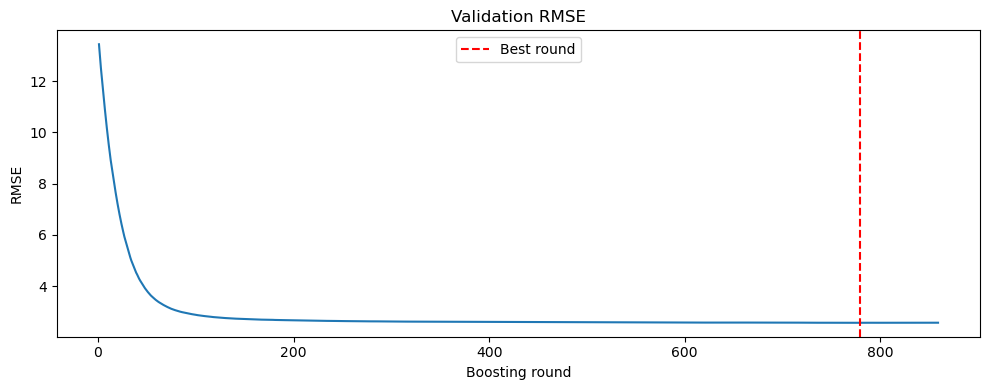

RMSE: 1.813
MAE: 1.343
R2: 0.947


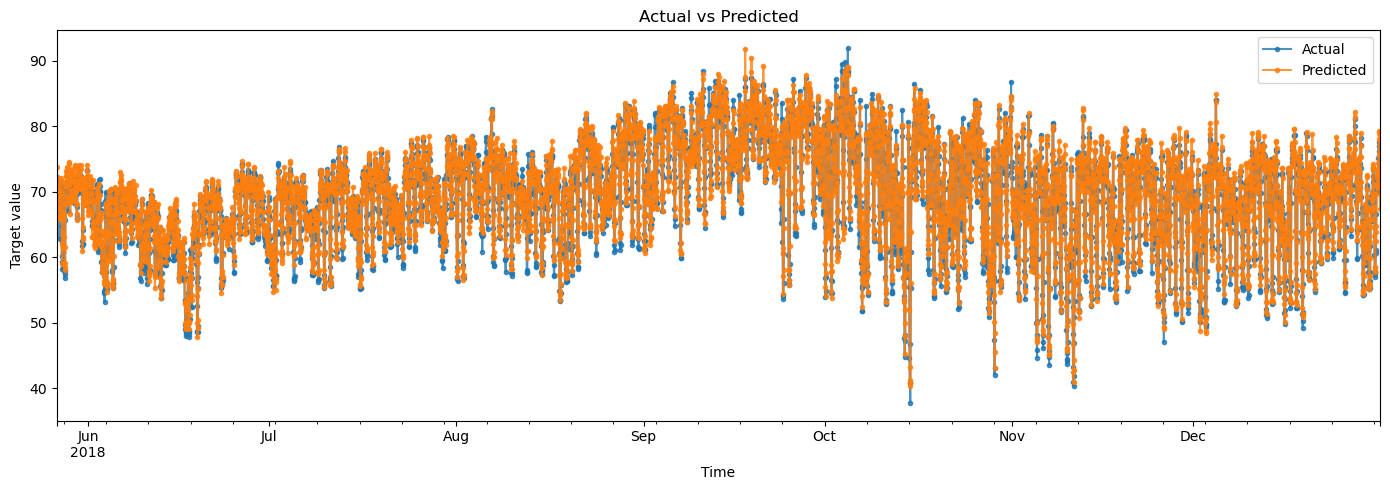

In [56]:
print('Best boosting round:', tree.best_iteration + 1)
print('Best validation RMSE:', tree.best_score)

history = tree.evals_result()
val_rmse = history['validation_0']['rmse']
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(range(1, len(val_rmse) + 1), val_rmse)
ax.axvline(
    tree.best_iteration + 1,
    color='red', linestyle='--', label='Best round'
)

ax.set(xlabel='Boosting round', ylabel='RMSE', title='Validation RMSE')
ax.legend()
plt.tight_layout()
plt.show()

Y_pred = tree.predict(X_test)
rmse = np.sqrt(mean_squared_error(Y_test, Y_pred))
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print(f'RMSE: {rmse:.3f}')
print(f'MAE: {mae:.3f}')
print(f'R2: {r2:.3f}')

comparison = pd.DataFrame({
    'Actual': Y_test,
    'Predicted': Y_pred
}, index=Y_test.index)

fig, ax = plt.subplots(figsize=(14, 5))
comparison.plot(ax=ax, marker='.', alpha=0.8)

ax.set_title('Actual vs Predicted')
ax.set_xlabel('Time')
ax.set_ylabel('Target value')
plt.tight_layout()
plt.show()

In [57]:
linear = make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                       StandardScaler(), Ridge(alpha=10))
linear.fit(X_train, Y_train)
linear_train = linear.predict(X_train)
linear_valid = linear.predict(X_val)

tree = XGBRegressor(**XGB_PARAMS, early_stopping_rounds=EARLY_STOPPING_ROUNDS)
tree.fit(X_train, Y_train - linear_train, eval_set=[(X_val, Y_val - linear_valid)], verbose=200)

[0]	validation_0-rmse:2.82586
[200]	validation_0-rmse:2.70754
[400]	validation_0-rmse:2.67233
[600]	validation_0-rmse:2.65491
[800]	validation_0-rmse:2.65325
[906]	validation_0-rmse:2.65205


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,80
,enable_categorical,False
,eval_metric,'rmse'


Best boosting round: 827
Best validation RMSE: 2.650051981201848


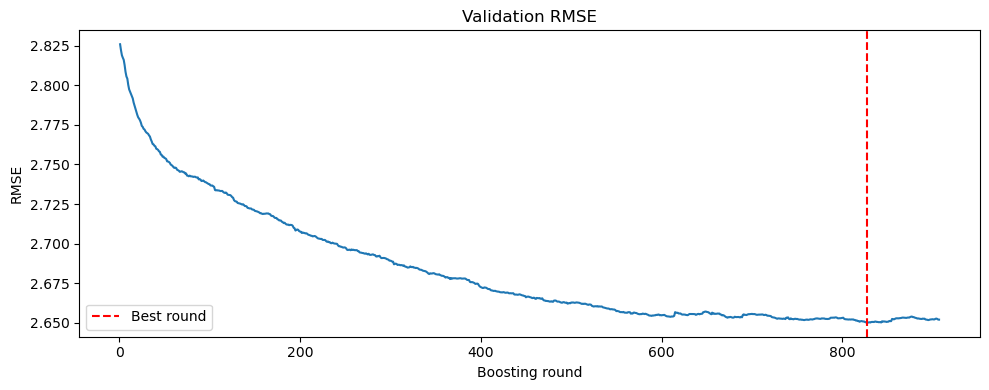

RMSE: 1.898
MAE: 1.421
R2: 0.942


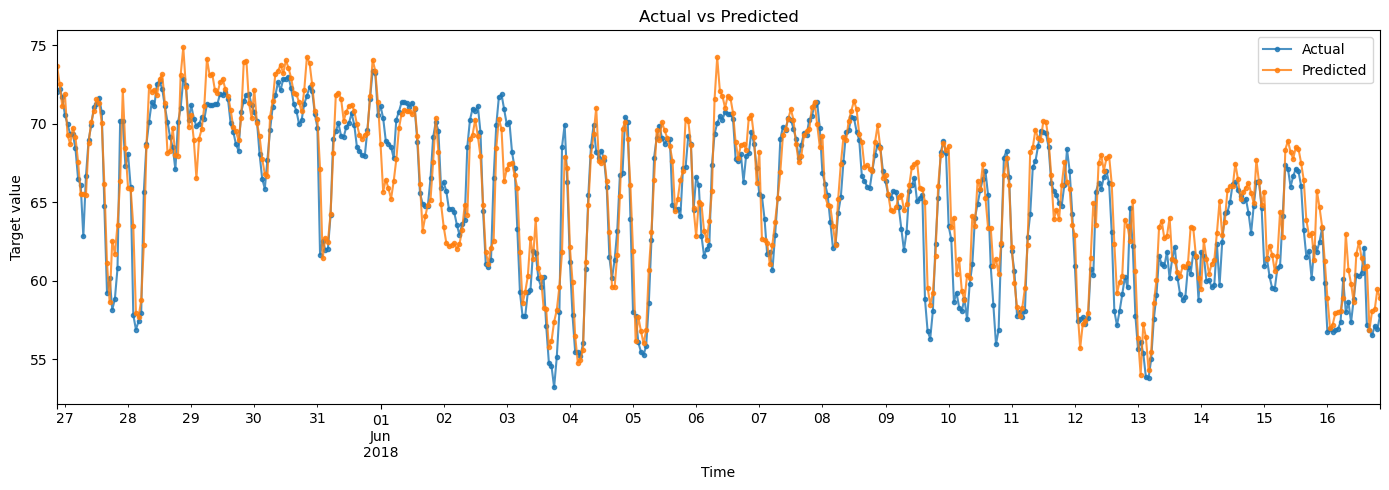

In [58]:
print('Best boosting round:', tree.best_iteration + 1)
print('Best validation RMSE:', tree.best_score)

history = tree.evals_result()
val_rmse = history['validation_0']['rmse']
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(range(1, len(val_rmse) + 1), val_rmse)
ax.axvline(
    tree.best_iteration + 1,
    color='red', linestyle='--', label='Best round'
)

ax.set(xlabel='Boosting round', ylabel='RMSE', title='Validation RMSE')
ax.legend()
plt.tight_layout()
plt.show()

Y_pred = tree.predict(X_test) + linear.predict(X_test)
rmse = np.sqrt(mean_squared_error(Y_test, Y_pred))
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print(f'RMSE: {rmse:.3f}')
print(f'MAE: {mae:.3f}')
print(f'R2: {r2:.3f}')

comparison = pd.DataFrame({
    'Actual': Y_test,
    'Predicted': Y_pred
}, index=Y_test.index)

fig, ax = plt.subplots(figsize=(14, 5))
comparison.iloc[:3*168].plot(ax=ax, marker='.', alpha=0.8)

ax.set_title('Actual vs Predicted')
ax.set_xlabel('Time')
ax.set_ylabel('Target value')
plt.tight_layout()
plt.show()

In [59]:
from sklearn.model_selection import ParameterSampler

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


# Start from your existing configuration.
base_params = XGB_PARAMS.copy()

# This is a cap, not the number that every model will use.
base_params["n_estimators"] = 3000

# Keep early stopping separate from the parameters used for final refitting.
base_params.pop("early_stopping_rounds", None)

search_space = {
    "max_depth": [2, 3, 4, 5, 6],
    "min_child_weight": [5, 10, 20, 40],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_lambda": [1.0, 5.0, 10.0, 30.0],
    "reg_alpha": [0.0, 0.1, 1.0],
}

# The empty dictionary includes your current parameter values.
candidates = [{}] + list(
    ParameterSampler(
        search_space,
        n_iter=24,
        random_state=42
    )
)

results = []
best_val_rmse = np.inf
selected_params = None
selected_model = None

for trial, changes in enumerate(candidates, start=1):
    params = {**base_params, **changes}

    candidate = XGBRegressor(
        **params,
        early_stopping_rounds=80
    )

    candidate.fit(
        X_train,
        Y_train,
        eval_set=[(X_val, Y_val)],
        verbose=False
    )

    val_pred = candidate.predict(X_val)

    score = rmse(Y_val, val_pred)
    mae = mean_absolute_error(Y_val, val_pred)
    best_rounds = candidate.best_iteration + 1

    results.append({
        "trial": trial,
        **params,
        "val_rmse": score,
        "val_mae": mae,
        "best_rounds": best_rounds,
    })

    if score < best_val_rmse:
        best_val_rmse = score

        # Store the selected tree count for the final fresh refit.
        selected_params = {
            **params,
            "n_estimators": best_rounds
        }

        selected_model = candidate

    print(
        f"Trial {trial:02d}: "
        f"validation RMSE={score:.4f}, "
        f"best rounds={best_rounds}"
    )

search_results = (
    pd.DataFrame(results)
    .sort_values("val_rmse")
    .reset_index(drop=True)
)

display(
    search_results[[
        "trial",
        "val_rmse",
        "val_mae",
        "best_rounds",
        "max_depth",
        "min_child_weight",
        "reg_lambda",
        "reg_alpha",
        "subsample",
        "colsample_bytree",
    ]].head(10)
)

print("Selected parameters:", selected_params)

Trial 01: validation RMSE=2.5713, best rounds=779
Trial 02: validation RMSE=2.5418, best rounds=519
Trial 03: validation RMSE=2.5917, best rounds=559
Trial 04: validation RMSE=2.5594, best rounds=558
Trial 05: validation RMSE=2.5913, best rounds=904
Trial 06: validation RMSE=2.6664, best rounds=2060
Trial 07: validation RMSE=2.5622, best rounds=648
Trial 08: validation RMSE=2.5962, best rounds=949
Trial 09: validation RMSE=2.5968, best rounds=1086
Trial 10: validation RMSE=2.6419, best rounds=763
Trial 11: validation RMSE=2.5541, best rounds=504
Trial 12: validation RMSE=2.5692, best rounds=419
Trial 13: validation RMSE=2.5523, best rounds=618
Trial 14: validation RMSE=2.7115, best rounds=1395
Trial 15: validation RMSE=2.5741, best rounds=581
Trial 16: validation RMSE=2.6144, best rounds=558
Trial 17: validation RMSE=2.7135, best rounds=1376
Trial 18: validation RMSE=2.7036, best rounds=1733
Trial 19: validation RMSE=2.5968, best rounds=1079
Trial 20: validation RMSE=2.5704, best round

,trial,val_rmse,val_mae,best_rounds,max_depth,min_child_weight,reg_lambda,reg_alpha,subsample,colsample_bytree
0,2,2.541752,1.715456,519,6,10,5.0,1.0,0.7,1.0
1,21,2.546324,1.735781,635,5,10,10.0,1.0,1.0,1.0
2,13,2.552254,1.726860,618,5,40,10.0,1.0,0.8,1.0
3,11,2.554063,1.725423,504,6,40,30.0,1.0,0.7,1.0
4,4,2.559386,1.730576,558,6,10,30.0,0.1,0.7,1.0
5,7,2.562170,1.745351,648,4,10,5.0,0.1,0.8,1.0
6,23,2.563408,1.738916,642,5,10,5.0,0.1,0.8,0.8
7,12,2.569158,1.736975,419,6,20,1.0,1.0,1.0,0.6
8,20,2.570377,1.755058,933,4,40,30.0,0.0,0.7,1.0
9,1,2.571332,1.753813,779,4,10,10.0,0.1,0.8,0.8


Selected parameters: {'objective': 'reg:squarederror', 'tree_method': 'hist', 'n_estimators': 519, 'learning_rate': 0.04, 'max_depth': 6, 'min_child_weight': 10, 'subsample': 0.7, 'colsample_bytree': 1.0, 'reg_lambda': 5.0, 'reg_alpha': 1.0, 'eval_metric': 'rmse', 'random_state': 42, 'n_jobs': 4}


In [77]:
TEST_START = train_end = int(len(supply) * 0.7)
N_SPLITS = 4
FOLD_HOURS = 24 * 7 * 13

dev_mask = X_clean.index < test_start
X_dev, Y_dev = X_clean.loc[dev_mask], Y_clean.loc[dev_mask]

cv = TimeSeriesSplit(
    n_splits=N_SPLITS,
    test_size=FOLD_HOURS,
    gap=0
)


def rmse(y_true, y_pred):
    return float(
        np.sqrt(
            np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)
        )
    )


def mae(y_true, y_pred):
    return float(
        np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)))
    )


def cross_validate(fit_predict, X, y, cv):
    fold_rmse, oof = [], pd.Series(np.nan, index=y.index)

    for train_idx, valid_idx in cv.split(X):
        pred = np.asarray(
            fit_predict(
                X.iloc[train_idx],
                y.iloc[train_idx],
                X.iloc[valid_idx]
            )
        )
        oof.iloc[valid_idx] = pred
        fold_rmse.append(rmse(y.iloc[valid_idx], pred))

    return np.array(fold_rmse), oof


cv_scores, oof_preds = {}, {}


def record(name, fold_rmse, oof):
    cv_scores[name], oof_preds[name] = fold_rmse, oof

    print(
        f'{name:31s} CV RMSE {fold_rmse.mean():6.3f} '
        f'± {fold_rmse.std():.3f}   per fold {np.round(fold_rmse, 2)}'
    )


BASELINES = {
    'persistence (t-1)': lambda X_tr, y_tr, X_va: X_va['price actual_lag1']
}

for name, fit_predict in BASELINES.items():
    record(name, *cross_validate(fit_predict, X_dev, Y_dev, cv))

persistence (t-1)               CV RMSE  3.522 ± 0.824   per fold [2.22 3.6  4.5  3.77]


In [78]:
SEED = 42

import os

N_JOBS = max(1, (os.cpu_count() or 2) // 2)

XGB_BASE = dict(
    objective='reg:squarederror',
    tree_method='hist',
    learning_rate=0.05,
    n_estimators=5000,
    random_state=SEED,
    n_jobs=N_JOBS
)

EARLY_STOP_HOURS = 24 * 28
EARLY_STOP_ROUNDS = 100


def fit_xgb(X_train, y_train, params, n_estimators=None):
    if n_estimators is not None:
        return XGBRegressor(
            **{
                **XGB_BASE,
                **params,
                'n_estimators': n_estimators
            }
        ).fit(X_train, y_train)

    X_fit, y_fit = (
        X_train.iloc[:-EARLY_STOP_HOURS],
        y_train.iloc[:-EARLY_STOP_HOURS]
    )

    X_stop, y_stop = (
        X_train.iloc[-EARLY_STOP_HOURS:],
        y_train.iloc[-EARLY_STOP_HOURS:]
    )

    model = XGBRegressor(
        **{**XGB_BASE, **params},
        early_stopping_rounds=EARLY_STOP_ROUNDS
    )

    model.fit(
        X_fit,
        y_fit,
        eval_set=[(X_stop, y_stop)],
        verbose=False
    )

    return model


def xgb_cv(params, X, y, cv):
    """Cross-validate one configuration. Also returns the median number of boosting rounds."""
    rounds = []

    def fit_predict(X_tr, y_tr, X_va):
        model = fit_xgb(X_tr, y_tr, params)
        rounds.append(model.best_iteration + 1)
        return model.predict(X_va)  # uses the best iteration automatically

    fold_rmse, oof = cross_validate(fit_predict, X, y, cv)

    return fold_rmse, oof, int(np.median(rounds))

In [79]:
SECOND_TRY_PARAMS = dict(
    max_depth=4,
    min_child_weight=10,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=10.0,
    reg_alpha=0.1,
    gamma=0.0
)

SEARCH_SPACE = {
    'max_depth': [3, 4, 5, 6, 8],
    'min_child_weight': [1, 5, 10, 20, 50],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.5, 0.7, 0.9, 1.0],
    'reg_lambda': [0.1, 1.0, 10.0, 50.0],
    'reg_alpha': [0.0, 0.1, 1.0, 10.0],
    'gamma': [0.0, 0.1, 1.0],
}

N_CANDIDATES = 15

candidates = [SECOND_TRY_PARAMS] + list(
    ParameterSampler(
        SEARCH_SPACE,
        n_iter=N_CANDIDATES,
        random_state=SEED
    )
)

search_rows, search_folds, search_oof = [], {}, {}

for i, params in enumerate(candidates):  # candidate 0 = second_try's settings, as a reference
    folds, oof, rounds = xgb_cv(params, X_dev, Y_dev, cv)

    search_rows.append({
        'candidate': i,
        **params,
        'cv_rmse': folds.mean(),
        'fold_std': folds.std(),
        'rounds': rounds
    })

    search_folds[i], search_oof[i] = folds, oof

    print(
        f'candidate {i:2d}: CV RMSE {folds.mean():.3f}  rounds {rounds:4d}'
    )

search = (
    pd.DataFrame(search_rows)
    .set_index('candidate')
    .sort_values('cv_rmse')
)

search.head(8)

candidate  0: CV RMSE 2.198  rounds 1023
candidate  1: CV RMSE 2.225  rounds 1113
candidate  2: CV RMSE 2.215  rounds  513
candidate  3: CV RMSE 2.205  rounds  593
candidate  4: CV RMSE 2.218  rounds 1399
candidate  5: CV RMSE 2.233  rounds  974
candidate  6: CV RMSE 2.172  rounds  262
candidate  7: CV RMSE 2.173  rounds  563
candidate  8: CV RMSE 2.211  rounds  558
candidate  9: CV RMSE 2.240  rounds  737
candidate 10: CV RMSE 2.264  rounds 1054
candidate 11: CV RMSE 2.179  rounds  671
candidate 12: CV RMSE 2.214  rounds  583
candidate 13: CV RMSE 2.216  rounds  542
candidate 14: CV RMSE 2.148  rounds  610
candidate 15: CV RMSE 2.185  rounds  632


,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,gamma,cv_rmse,fold_std,rounds
candidate,,,,,,,,,,
14,6,10,1.0,1.0,10.0,0.1,0.0,2.147623,0.412718,610
6,8,50,0.6,1.0,0.1,0.1,0.0,2.171744,0.427933,262
7,5,1,0.8,1.0,1.0,0.0,0.0,2.172508,0.415863,563
11,4,5,1.0,1.0,0.1,10.0,1.0,2.179217,0.424211,671
15,5,5,1.0,1.0,50.0,1.0,0.0,2.184685,0.431908,632
0,4,10,0.8,0.8,10.0,0.1,0.0,2.198045,0.421705,1023
3,5,10,1.0,0.7,0.1,0.1,0.1,2.204984,0.432903,593
8,6,50,0.8,0.7,50.0,0.1,0.1,2.210524,0.447646,558


In [80]:
order = search.index.to_list()
best_id = order[0]

XGB_PARAMS = {
    k: (
        int(search.loc[best_id, k])
        if k == 'max_depth'
        else float(search.loc[best_id, k])
    )
    for k in SEARCH_SPACE
}

XGB_ROUNDS = int(search.loc[best_id, 'rounds'])

print(
    'chosen parameters:',
    XGB_PARAMS,
    '| boosting rounds:',
    XGB_ROUNDS
)

chosen parameters: {'max_depth': 6, 'min_child_weight': 10.0, 'subsample': 1.0, 'colsample_bytree': 1.0, 'reg_lambda': 10.0, 'reg_alpha': 0.1, 'gamma': 0.0} | boosting rounds: 610


In [81]:
xgb_final = fit_xgb(
    X_dev,
    Y_dev,
    XGB_PARAMS,
    n_estimators=XGB_ROUNDS
)

test_pred = pd.DataFrame(
    {
        'persistence (t-1)': X_test['price actual_lag1'],
        'XGB (tuned)': xgb_final.predict(X_test)
    },
    index=X_test.index
)


def metrics_table(y_true, predictions, reference):
    table = pd.DataFrame({
        name: {
            'RMSE': rmse(y_true, p),
            'MAE': mae(y_true, p),
            'R2': (
                1
                - np.sum((y_true - p) ** 2)
                / np.sum((y_true - y_true.mean()) ** 2)
            ),
            'bias (mean error)': float(np.mean(y_true - p))
        }
        for name, p in predictions.items()
    }).T

    table[f'skill vs {reference}'] = (
        1 - table['RMSE'] / table.loc[reference, 'RMSE']
    )

    return table.sort_values('RMSE')


test_table = metrics_table(
    Y_test,
    test_pred,
    reference='persistence (t-1)'
)

display(test_table)

,RMSE,MAE,R2,bias (mean error),skill vs persistence (t-1)
XGB (tuned),1.736470,1.272452,0.951724,-0.135375,0.396536
persistence (t-1),2.877506,1.972150,0.867434,-0.000036,0.000000


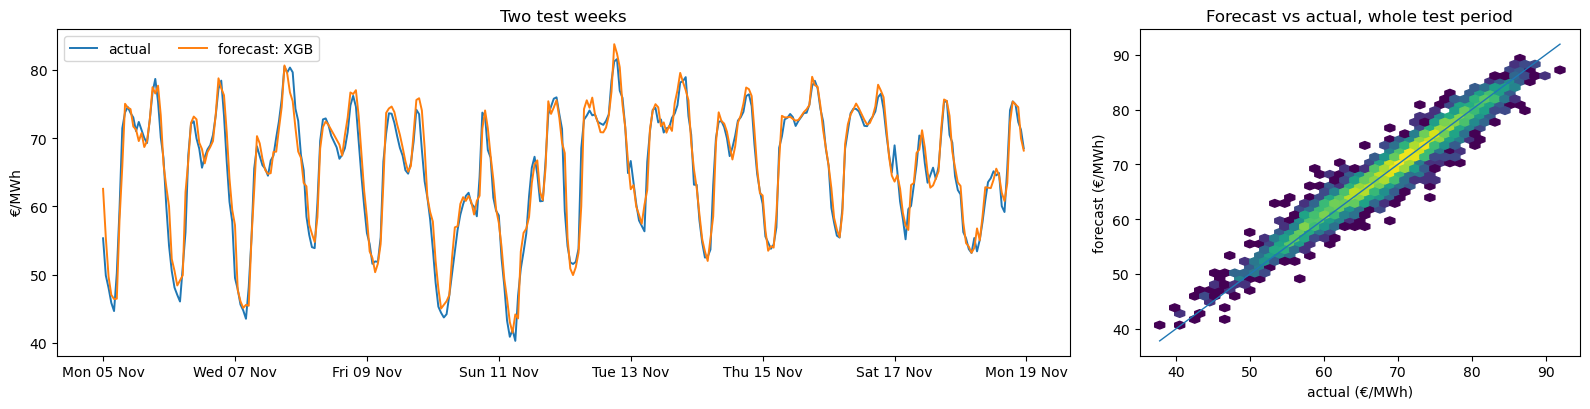

In [82]:
best_pred = test_pred['XGB (tuned)']
weeks = slice('2018-11-05', '2018-11-18')

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 4.2),
    gridspec_kw={'width_ratios': [2.3, 1]}
)

axes[0].plot(
    Y_test.loc[weeks].index,
    Y_test.loc[weeks],
    linewidth=1.4,
    label='actual'
)

axes[0].plot(
    best_pred.loc[weeks].index,
    best_pred.loc[weeks],
    linewidth=1.4,
    label=f'forecast: XGB'
)

axes[0].set(
    title='Two test weeks',
    ylabel='€/MWh'
)

axes[0].xaxis.set_major_formatter(
    mdates.DateFormatter('%a %d %b', tz='Europe/Madrid')
)

axes[0].legend(loc='upper left', ncol=2)

axes[1].hexbin(
    Y_test,
    best_pred,
    gridsize=40,
    mincnt=1,
    bins='log'
)

lims = [Y_test.min(), Y_test.max()]
axes[1].plot(lims, lims, linewidth=1)

axes[1].set(
    title='Forecast vs actual, whole test period',
    xlabel='actual (€/MWh)',
    ylabel='forecast (€/MWh)'
)

axes[1].grid(False)

plt.tight_layout()
plt.show()